# Ejercicio 6. capas en Iris




In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
import importlib.util
import json
import platform
import sys
from pathlib import Path
from time import perf_counter

# Si falta algún paquete, lo instalo aquí.
required = {"numpy": "numpy", "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tensorflow": "tensorflow", "pandas": "pandas"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
SEED = 42
EN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
ENTORNO = "Google Colab" if EN_COLAB else "Ejecución local"
print(ENTORNO)
print("Python:", platform.python_version(), "| Sistema:", platform.platform())
print("Semilla:", SEED, "| Épocas: 500 | Tasa: 0.03")

Ejecución local
Python: 3.11.18 | Sistema: macOS-26.6.2-arm64-arm-64bit
Semilla: 42 | Épocas: 500 | Tasa: 0.03


## 1. Primero, la red de clase en Keras

Empiezo con las dos capas Dense de 3 neuronas que trae el ejemplo.
Uso `keras.Input(shape=(4,))` para indicar las 4 entradas; eso no agrega otra
capa que aprenda. También fijo la semilla y tomo el tiempo.

Dejo `verbose=0` para no llenar el cuaderno con 500 barras de progreso.
Después muestro cómo iba el error cada 50 épocas.

Keras trabaja con grupos de 32 flores y las mezcla en cada época.
NumPy las toma de una en una y en orden por especie. También arrancan con
pesos distintos, así que sus curvas pueden salir diferentes.


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn import datasets

In [3]:
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [4]:
iris = datasets.load_iris()
X = iris.data
target = iris.target
Y = to_categorical(target).astype("uint8")
# 0 => [1 0 0]
# 1 => [0 1 0]
# 2 => [0 0 1]

In [5]:
idx = 0
print(X[idx])
print(target[idx])
print(Y[idx])

[5.1 3.5 1.4 0.2]
0
[1 0 0]


In [6]:
model = keras.Sequential(
  [
    keras.Input(shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer1"),
    layers.Dense(3, activation="sigmoid", name="layer2"),
  ]
)

model.summary()
lineas_summary = []
model.summary(print_fn=lambda line: lineas_summary.append(line))
(RESULTADOS / "keras_original_summary.txt").write_text("\n".join(lineas_summary))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (108.00 B)

 Trainable params: 27 (108.00 B)

 Non-trainable params: 0 (0.00 B)

655

In [7]:
y = model(X)
print(y[149])

tf.Tensor([0.75035655 0.497021   0.5582424 ], shape=(3,), dtype=float32)


In [8]:
optimizer=tf.keras.optimizers.SGD(learning_rate=0.03)
loss=tf.keras.losses.MeanSquaredError()

model.compile(optimizer, loss)
inicio_original = perf_counter()
history = model.fit(X, Y, epochs=500, verbose=0)
tiempo_original = perf_counter() - inicio_original
print("Entrenamiento original: 500 épocas completas")

Entrenamiento original: 500 épocas completas


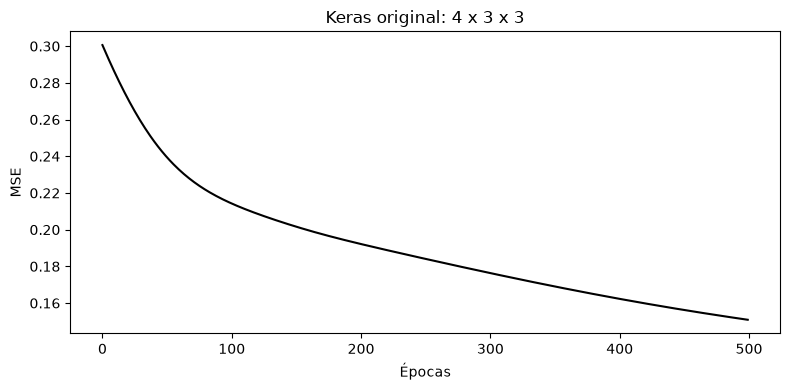

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], color='black')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.title('Keras original: 4 x 3 x 3')
plt.tight_layout()
plt.savefig(RESULTADOS / 'keras_original_curva.png', dpi=160)
plt.show()

In [10]:
# La gráfica ya quedó guardada en la celda de arriba.
print('Loss final registrada por fit:', history.history['loss'][-1])

Loss final registrada por fit: 0.15090696513652802


In [11]:
model.predict(np.array([[3,3,1,1]]))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


array([[0.5178732 , 0.28180325, 0.19554119]], dtype=float32)

In [12]:
pred_original = model(X, training=False).numpy()
metricas_original = {
    "topologia": [4, 3, 3],
    "loss_ultima_epoca": float(history.history["loss"][-1]),
    "mse_final": float(np.mean((Y - pred_original) ** 2)),
    "precision_entrenamiento": float(np.mean(pred_original.argmax(axis=1) == target)),
    "segundos": tiempo_original,
    "parametros": int(model.count_params()),
}
print("CORRIDA ORIGINAL KERAS")
for key, value in metricas_original.items():
    print(key, ":", value)
for epoch in range(49, 500, 50):
    print(f"Época {epoch + 1:3d}: loss = {history.history['loss'][epoch]:.6f}")
print("Predicción [3,3,1,1]:", model(np.array([[3, 3, 1, 1]]), training=False).numpy()[0])

CORRIDA ORIGINAL KERAS
topologia : [4, 3, 3]
loss_ultima_epoca : 0.15090696513652802
mse_final : 0.15083874762058258
precision_entrenamiento : 0.6666666666666666
segundos : 4.689981291998265
parametros : 27
Época  50: loss = 0.240165
Época 100: loss = 0.214559
Época 150: loss = 0.201811
Época 200: loss = 0.192328
Época 250: loss = 0.184212
Época 300: loss = 0.176478
Época 350: loss = 0.169161
Época 400: loss = 0.162416
Época 450: loss = 0.156328
Época 500: loss = 0.150907
Predicción [3,3,1,1]: [0.5178732  0.28180325 0.19554119]


## 2. Ahora le pongo dos capas más


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer4 (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51 (204.00 B)

 Trainable params: 51 (204.00 B)

 Non-trainable params: 0 (0.00 B)

CORRIDA PROFUNDA KERAS
topologia : [4, 3, 3, 3, 3]
loss_ultima_epoca : 0.22171808779239655
mse_final : 0.22171393036842346
precision_entrenamiento : 0.5
segundos : 5.197332499999902
parametros : 51
Época  50: loss = 0.256202
Época 100: loss = 0.235026
Época 150: loss = 0.227257
Época 200: loss = 0.224189
Época 250: loss = 0.222882
Época 300: loss = 0.222289
Época 350: loss = 0.222004
Época 400: loss = 0.221857
Época 450: loss = 0.221773
Época 500: loss = 0.221718
Predicción [3,3,1,1]: [0.34232172 0.33883744 0.33637056]


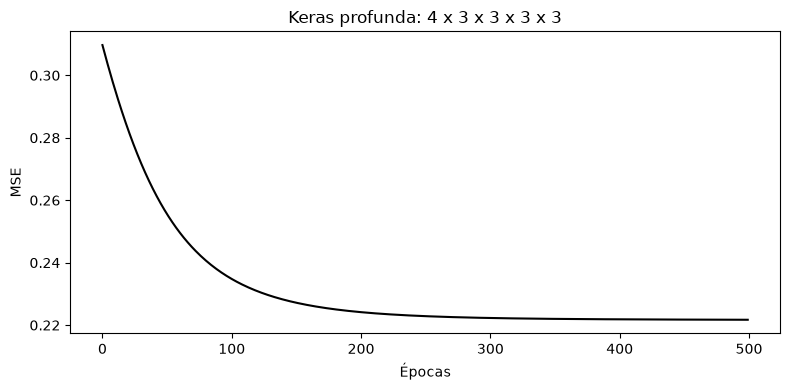

In [13]:
# Dejo la misma semilla y la misma forma de entrenar.
# Aquí agrego dos capas Dense de 3 neuronas.
keras.utils.set_random_seed(SEED)
model_profundo = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer1"),
    layers.Dense(3, activation="sigmoid", name="layer2"),
    layers.Dense(3, activation="sigmoid", name="layer3"),
    layers.Dense(3, activation="sigmoid", name="layer4"),
])
model_profundo.summary()
assert len(model_profundo.layers) == 4
assert model_profundo.output_shape == (None, 3)
lineas_summary = []
model_profundo.summary(print_fn=lambda line: lineas_summary.append(line))
(RESULTADOS / "keras_profunda_summary.txt").write_text("\n".join(lineas_summary))
model_profundo.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.03),
    loss=keras.losses.MeanSquaredError(),
)
inicio_profundo = perf_counter()
history_profunda = model_profundo.fit(X, Y, epochs=500, verbose=0)
tiempo_profundo = perf_counter() - inicio_profundo
pred_profunda = model_profundo(X, training=False).numpy()
metricas_profunda = {
    "topologia": [4, 3, 3, 3, 3],
    "loss_ultima_epoca": float(history_profunda.history["loss"][-1]),
    "mse_final": float(np.mean((Y - pred_profunda) ** 2)),
    "precision_entrenamiento": float(np.mean(pred_profunda.argmax(axis=1) == target)),
    "segundos": tiempo_profundo,
    "parametros": int(model_profundo.count_params()),
}
print("CORRIDA PROFUNDA KERAS")
for key, value in metricas_profunda.items():
    print(key, ":", value)
for epoch in range(49, 500, 50):
    print(f"Época {epoch + 1:3d}: loss = {history_profunda.history['loss'][epoch]:.6f}")
print("Predicción [3,3,1,1]:", model_profundo(np.array([[3, 3, 1, 1]]), training=False).numpy()[0])
plt.figure(figsize=(8, 4))
plt.plot(history_profunda.history["loss"], color="black")
plt.xlabel("Épocas")
plt.ylabel("MSE")
plt.title("Keras profunda: 4 x 3 x 3 x 3 x 3")
plt.tight_layout()
plt.savefig(RESULTADOS / "keras_profunda_curva.png", dpi=160)
plt.show()

## 3. Comparo las dos redes


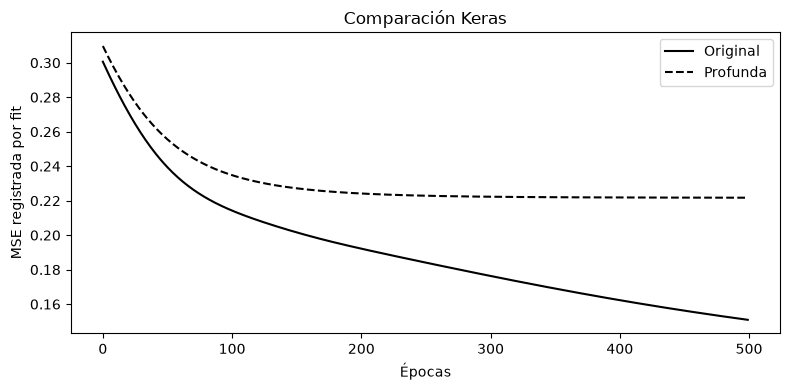

MSE original: 0.15083874762058258
MSE profunda: 0.22171393036842346
Cambio de MSE (profunda - original): 0.07087518274784088
Más capas no garantizan mejor resultado: varias sigmoides reducen el gradiente.


In [14]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], color="black", label="Original")
plt.plot(history_profunda.history["loss"], color="black", linestyle="--", label="Profunda")
plt.xlabel("Épocas")
plt.ylabel("MSE registrada por fit")
plt.title("Comparación Keras")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "keras_comparacion.png", dpi=160)
plt.show()
metricas_keras = {"entorno": ENTORNO, "semilla": SEED, "epocas": 500, "tasa": 0.03,
                 "original": metricas_original, "profunda": metricas_profunda}
(RESULTADOS / "keras_metricas.json").write_text(json.dumps(metricas_keras, ensure_ascii=False, indent=2))
print("MSE original:", metricas_original["mse_final"])
print("MSE profunda:", metricas_profunda["mse_final"])
print("Cambio de MSE (profunda - original):", metricas_profunda["mse_final"] - metricas_original["mse_final"])
print("Más capas no garantizan mejor resultado: varias sigmoides reducen el gradiente.")

En `model.summary()` salen 27 parámetros en la red original y 51 en la nueva.
La nueva tiene cuatro capas Dense; Input solo indica cuántos datos entran.

Las predicciones y los aciertos usan las mismas flores del entrenamiento.
Las capturas están en capturas.docx. Falta agregar la del cuaderno corriendo en Colab.


## 4. Cómo salieron las cuatro pruebas

Usé las mismas 150 flores, 500 épocas, aprendizaje de 0.03 y semilla 42.
Primero corrí la red de 4 x 3 x 3 y después la de 4 x 3 x 3 x 3 x 3.
Estos números salieron al correr los cuadernos en mi compu.

| Corrida | Red | MSE final | Aciertos en entrenamiento | Tiempo (s) |
| --- | --- | --- | --- | --- |
| NumPy original | 4 x 3 x 3 | 0.020930 | 96.00% | 2.01 |
| NumPy profunda | 4 x 3 x 3 x 3 x 3 | 0.135475 | 70.67% | 2.91 |
| Keras original | 4 x 3 x 3 | 0.150839 | 66.67% | 4.69 |
| Keras profunda | 4 x 3 x 3 x 3 x 3 | 0.221714 | 50.00% | 5.20 |

Con dos capas más, el error subió en las dos versiones. En NumPy pasó de
0.020930 a 0.135475 y los aciertos bajaron de 96.00% a 70.67%.
En Keras pasó de 0.150839 a 0.221714 y los aciertos bajaron de 66.67% a 50.00%.
En esta prueba, poner más capas no ayudó.

Las curvas no salieron iguales. NumPy cambia los pesos después de cada flor
y sigue el orden de las especies. Keras mezcla las flores y trabaja con grupos
de 32. También empiezan con pesos distintos. Para comparar los errores usé
MSE por salida; el error original de NumPy es tres veces ese valor porque
suma las tres salidas.

Además, encontré el detalle de los índices en el código NumPy de clase.
Ese código también cambia los pesos de salida antes de sacar el error oculto.
Lo dejé así en la primera prueba y lo arreglé en la red nueva. Por eso,
no todo el cambio de NumPy viene de poner más capas.

Con varias sigmoides seguidas, los ajustes que llegan a las primeras capas
pueden hacerse muy pequeños. Eso ayuda a entender por qué las redes nuevas
aprendieron más lento. Los aciertos son sobre las flores del entrenamiento;
todavía falta probar con otras flores. En Keras, la red original tiene 2 capas
Dense y 27 parámetros, y la nueva tiene 4 capas Dense y 51 parámetros.
